# Activity 2: Simple House Price Prediction
## Unit II: Supervised Learning — Regression
### Machine Learning CIE 2 Project

---

### Project Title
**Simple House Price Prediction Using Linear Regression on California Housing Data**

### Student & Course Information
- **Course**: Machine Learning Laboratory (CIE 2)
- **Unit**: Unit II — Supervised Learning: Regression
- **Activity**: Activity 2 — Simple House Price Prediction
- **Faculty Mentor**: [Princy2129](https://github.com/Princy2129)

### 1. Project Objective
The primary objective of this project is to construct an end-to-end, reproducible, beginner-friendly Supervised Machine Learning workflow that predicts continuous house prices using Simple Linear Regression. 

### 2. Problem Statement
House prices are heavily influenced by geographic, structural, and socio-economic variables. Among economic determinants, the income level of neighborhood residents is traditionally considered a major indicator of purchasing capacity. In this activity, we model the mathematical relationship between neighborhood median income (`MedInc`) and median house value (`MedHouseVal`), evaluate the fitted model on unseen test data using standard regression metrics, visualize performance, and generate predictions for new observations.

### 3. Understanding Supervised Learning and Regression
- **Supervised Learning**: A category of machine learning where an algorithm learns a mapping function from input features ($X$) to known ground-truth target labels ($y$) using historical training pairs $(X, y)$.
- **Regression**: A branch of supervised learning where the target variable is continuous and numerical (such as prices, temperatures, or heights), contrasting with classification where targets are discrete categorical classes.
- **Simple Linear Regression**: Models the relationship between a single independent predictor variable $X$ and a continuous dependent target variable $y$ via a linear equation:
  $$\hat{y} = eta_0 + eta_1 X$$
  where $eta_0$ is the y-intercept and $eta_1$ is the slope coefficient.

### 4. Technology Stack
- **Python**: Core programming language
- **Pandas**: Data manipulation, ingestion, and tabular inspection
- **NumPy**: Numerical computing and vector mathematics
- **Matplotlib & Seaborn**: Statistical data visualization and regression plotting
- **Scikit-learn**: Machine learning algorithms, dataset loading, data splitting, and performance metrics


## Section 2: Load and Understand the Dataset

In this section, we import all required libraries, load the standardized **California Housing dataset** directly from Scikit-learn, convert it into a structured Pandas DataFrame, and inspect its basic dimensions and structure.

**Dataset Background**:
- **Source**: Scikit-learn Real-World Datasets (`fetch_california_housing`), derived from the 1990 U.S. Census by Pace and Barry.
- **Target Variable (`MedHouseVal`)**: Median house value for households within a California census block group, expressed in units of **$100,000** (e.g., $4.526 = $452,600).
- **Suggested Feature (`MedInc`)**: Median income of households within a census block group, expressed in units of **$10,000** (e.g., $8.3252 = $83,252).


In [1]:
# Step 1: Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Set visualization style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (8, 5)

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:
# Step 2: Load the California Housing dataset
housing = fetch_california_housing(as_frame=True)
df = housing.frame

# Step 3: Display dimensions
print(f"Dataset Dimensions: {df.shape[0]} rows (block groups) and {df.shape[1]} columns")


Dataset Dimensions: 20640 rows (block groups) and 9 columns


In [3]:
# Display first 5 rows
print("--- First 5 Rows ---")
df.head()


--- First 5 Rows ---


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [4]:
# Display last 5 rows
print("--- Last 5 Rows ---")
df.tail()


--- Last 5 Rows ---


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847
20639,2.3886,16.0,5.254717,1.162264,1387.0,2.616981,39.37,-121.24,0.894


In [5]:
# Display column names, data types, and non-null counts
print("--- DataFrame Info ---")
df.info()


--- DataFrame Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [6]:
# Display descriptive summary statistics
print("--- Descriptive Summary Statistics ---")
df.describe()


--- Descriptive Summary Statistics ---


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


## Section 3: Data Quality Checks

Before training any machine learning model, rigorous quality checks are essential:
1. Verify whether missing (`NaN` or `null`) values exist in any column.
2. Check for duplicate rows that could bias model training or distort test evaluations.
3. Inspect data types and verify that numerical values fall within physically plausible boundaries.

*Data Cleaning Policy*: Records should only be removed or modified if genuine corruptions or duplicates exist. Unnecessary deletion reduces training sample diversity and damages generalization.


In [7]:
# Check missing values count and percentage per column
missing_counts = df.isnull().sum()
missing_percent = (missing_counts / len(df)) * 100

data_quality_df = pd.DataFrame({
    'Missing Count': missing_counts,
    'Missing Percentage (%)': missing_percent
})
print("--- Missing Values Analysis ---")
print(data_quality_df)


--- Missing Values Analysis ---
             Missing Count  Missing Percentage (%)
MedInc                   0                     0.0
HouseAge                 0                     0.0
AveRooms                 0                     0.0
AveBedrms                0                     0.0
Population               0                     0.0
AveOccup                 0                     0.0
Latitude                 0                     0.0
Longitude                0                     0.0
MedHouseVal              0                     0.0


In [8]:
# Check for exact duplicate records
duplicate_count = df.duplicated().sum()
print(f"Number of exact duplicate rows: {duplicate_count}")


Number of exact duplicate rows: 0


In [9]:
# Check min and max ranges for MedInc and MedHouseVal
print(f"MedInc Range: min = {df['MedInc'].min():.4f}, max = {df['MedInc'].max():.4f}")
print(f"MedHouseVal Range: min = {df['MedHouseVal'].min():.4f}, max = {df['MedHouseVal'].max():.4f}")

# Note on upper-boundary capping in census data:
capped_target_count = (df['MedHouseVal'] >= 5.0).sum()
print(f"Number of block groups capped at MedHouseVal >= 5.0 ($500,000+): {capped_target_count} ({capped_target_count / len(df) * 100:.2f}%)")


MedInc Range: min = 0.4999, max = 15.0001
MedHouseVal Range: min = 0.1500, max = 5.0000
Number of block groups capped at MedHouseVal >= 5.0 ($500,000+): 992 (4.81%)


### Data Cleaning Decisions Summary:
- **Missing Values**: 0 missing values across all 20,640 rows. No imputation is necessary.
- **Duplicates**: 0 duplicate rows. No deduplication required.
- **Value Plausibility**: All attributes are continuous floats. We observe that `MedHouseVal` was capped at 5.0 ($500,000) during 1990 census collection. As per standard machine learning protocol for this benchmark dataset, we retain all observations to preserve the complete benchmark distribution.


## Section 4: Select Input Features and Target

In this project, we implement a **Simple (Univariate) Linear Regression** model:
- **Input Feature ($X$)**: `MedInc` (Median Income in block group).
- **Target Variable ($y$)**: `MedHouseVal` (Median House Value in $100,000s).

### Academic Justifications:
1. **Why `MedInc` as predictor?** Economically, household income is the strongest single indicator of purchasing power and housing affordability. Neighborhoods with higher median incomes naturally exhibit higher property valuations.
2. **Why `MedHouseVal` as target?** The target represents a continuous numerical financial value measured in units of $100,000, making it an ideal candidate for regression analysis rather than classification.
3. **Why identifiers should NOT be used as features?** Unique identifiers, sequence indexes, or database IDs do not possess physical causal relevance. Using them creates spurious correlations and severe overfitting.


In [10]:
# Feature and Target Selection
# X must be a 2D array / DataFrame as expected by Scikit-learn
X = df[['MedInc']]

# y is a 1D Series representing continuous target values
y = df['MedHouseVal']

print(f"Shape of Input Feature Matrix (X): {X.shape}")
print(f"Shape of Target Vector (y): {y.shape}")


Shape of Input Feature Matrix (X): (20640, 1)
Shape of Target Vector (y): (20640,)


## Section 5: Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand distributions, uncover patterns, and visually verify linearity before modeling.

We will create:
1. **Scatter Plot of `MedInc` vs `MedHouseVal`** with an empirical trend line.
2. **Histogram & KDE Plot** of the target variable `MedHouseVal`.
3. **Correlation Heatmap** across all features in the dataset.


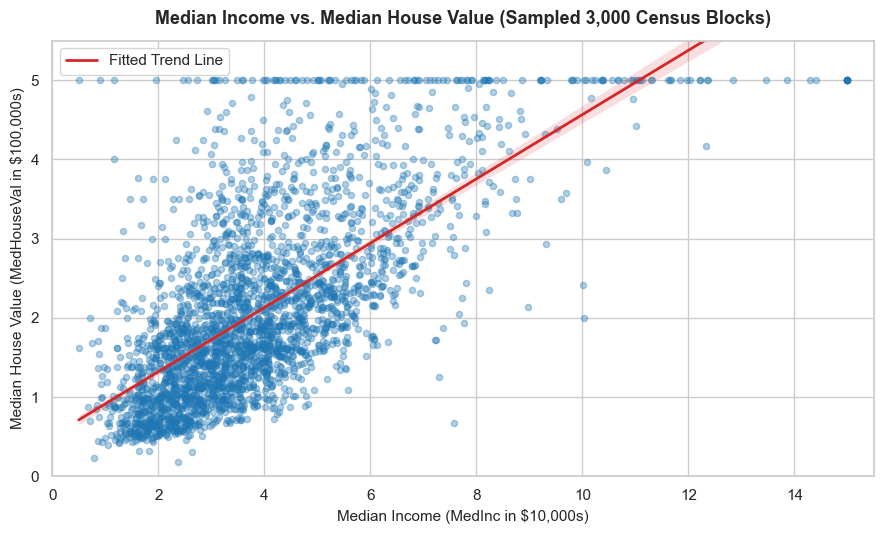

In [11]:
# 1. Scatter Plot: Median Income vs Median House Value
plt.figure(figsize=(9, 5.5))
sample_plot = df.sample(n=3000, random_state=42)

sns.regplot(
    data=sample_plot, x='MedInc', y='MedHouseVal',
    scatter_kws={'alpha': 0.35, 'color': '#1f77b4', 's': 20},
    line_kws={'color': '#d62728', 'linewidth': 2, 'label': 'Fitted Trend Line'}
)
plt.title("Median Income vs. Median House Value (Sampled 3,000 Census Blocks)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Median Income (MedInc in $10,000s)", fontsize=11)
plt.ylabel("Median House Value (MedHouseVal in $100,000s)", fontsize=11)
plt.ylim(0, 5.5)
plt.xlim(0, 15.5)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


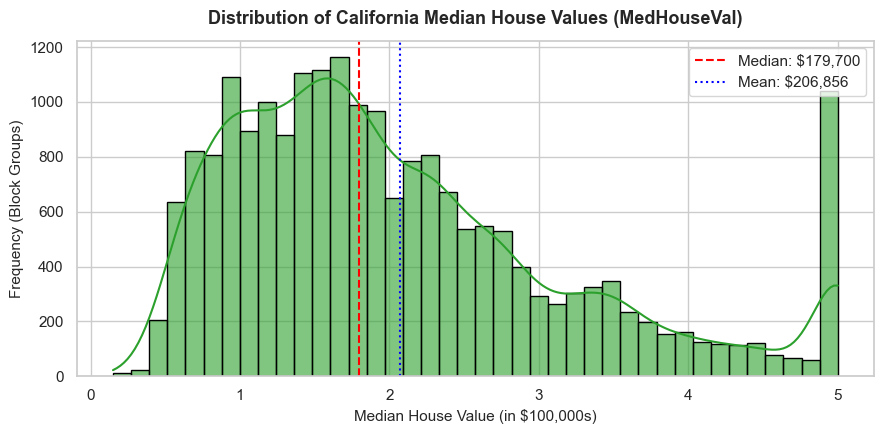

In [12]:
# 2. Distribution Plot: Median House Value (Target Variable)
plt.figure(figsize=(9, 4.5))
sns.histplot(df['MedHouseVal'], kde=True, bins=40, color='#2ca02c', edgecolor='black', alpha=0.6)
plt.axvline(df['MedHouseVal'].median(), color='red', linestyle='--', linewidth=1.5, label=f"Median: ${df['MedHouseVal'].median()*100000:,.0f}")
plt.axvline(df['MedHouseVal'].mean(), color='blue', linestyle=':', linewidth=1.5, label=f"Mean: ${df['MedHouseVal'].mean()*100000:,.0f}")
plt.title("Distribution of California Median House Values (MedHouseVal)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Median House Value (in $100,000s)", fontsize=11)
plt.ylabel("Frequency (Block Groups)", fontsize=11)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


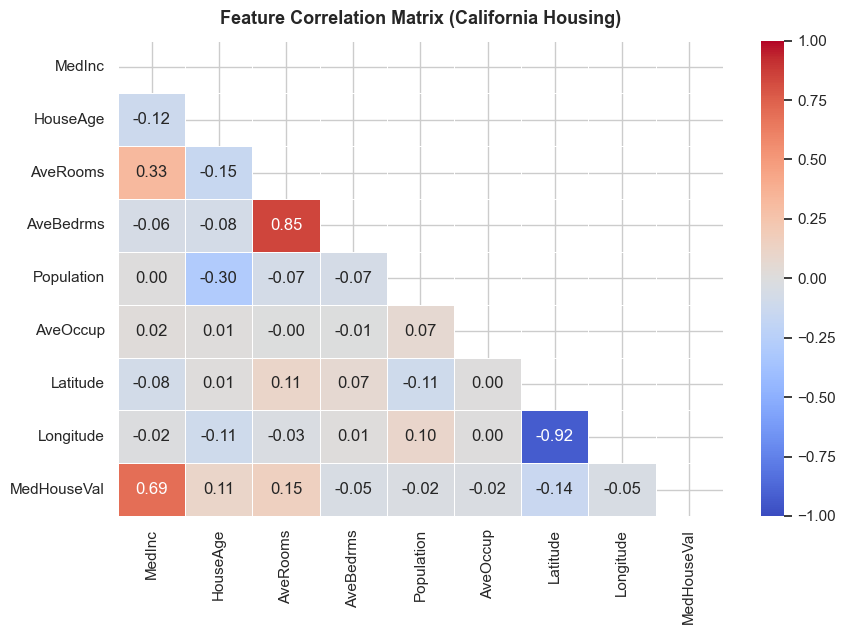

In [13]:
# 3. Correlation Heatmap across all numerical features
plt.figure(figsize=(9, 6.5))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, mask=mask, linewidths=0.5)
plt.title("Feature Correlation Matrix (California Housing)", fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


### Main Observations from EDA:
1. **Positive Moderate Relationship**: The scatter plot reveals a clear upward trend—as median income increases, median house values increase correspondingly. The Pearson correlation coefficient between `MedInc` and `MedHouseVal` is **+0.69**, making it by far the strongest individual predictor in the dataset.
2. **Capping Artifact**: A noticeable horizontal cluster of points appears at `MedHouseVal = 5.0`. This represents an upper-bound censorship in the 1990 census where all values above $500,000 were recorded as $500,000.
3. **Association vs. Causation**: While visual association and correlation are positive and substantial, statistical correlation alone **does not prove causation**. High income does not directly cause construction costs to rise; rather, wealthier households bid up prices in desirable neighborhoods.


## Section 6: Split the Dataset

To evaluate how well our model generalizes to unseen data, we partition the dataset into:
- **Training Set (80%)**: Used by the algorithm to learn the optimal parameters ($eta_0$ and $eta_1$).
- **Testing Set (20%)**: Held-out completely during training; used strictly for unbiased performance evaluation.

We set `random_state=42` to guarantee complete experimental reproducibility.


In [14]:
# Split the dataset into 80% train and 20% test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    random_state=42
)

# Display split dimensions
print(f"Total observations: {len(df)}")
print(f"Training observations (80%): {len(X_train)} rows")
print(f"Testing observations  (20%): {len(X_test)} rows")
print()
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape : {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape : {y_test.shape}")


Total observations: 20640
Training observations (80%): 16512 rows
Testing observations  (20%): 4128 rows

X_train shape: (16512, 1)
X_test shape : (4128, 1)
y_train shape: (16512,)
y_test shape : (4128,)


## Section 7: Train the Linear Regression Model

We import `LinearRegression` from `sklearn.linear_model`, initialize the estimator, and fit it using Ordinary Least Squares (OLS) exclusively on the training sets `X_train` and `y_train`.


In [15]:
# Initialize the Linear Regression model
model = LinearRegression()

# Fit the model ONLY on training data
model.fit(X_train, y_train)

# Extract learned parameters
slope_coef = model.coef_[0]
y_intercept = model.intercept_

print(f"Learned Coefficient (Slope beta_1) : {slope_coef:.4f}")
print(f"Learned Intercept (beta_0)          : {y_intercept:.4f}")
print()
print(f"Fitted Regression Equation:")
print(f"Predicted MedHouseVal = {y_intercept:.4f} + ({slope_coef:.4f} * MedInc)")


Learned Coefficient (Slope beta_1) : 0.4193
Learned Intercept (beta_0)          : 0.4446

Fitted Regression Equation:
Predicted MedHouseVal = 0.4446 + (0.4193 * MedInc)


### Interpretation of Learned Parameters:
- **Slope Coefficient ($eta_1 = 0.4193$)**: For every 1-unit increase in `MedInc` (which corresponds to a $10,000 increase in neighborhood median income), the predicted median house value increases by approximately **0.4193 units** (or approximately **$41,934**).
- **Y-Intercept ($eta_0 = 0.4446$)**: The mathematical baseline predicted house value when `MedInc = 0` is approximately **0.4446 units** (or **$44,460**). In practical terms, census blocks with zero income do not exist, so the intercept primarily anchors the linear equation rather than representing a realistic standalone market valuation.


## Section 8: Generate Test Predictions

We evaluate the model on the held-out test set `X_test`. To inspect individual prediction quality, we construct a comparison table showing actual values, model predictions, absolute errors, and their dollar conversions.


In [16]:
# Generate predictions on the unseen test set
y_pred = model.predict(X_test)

# Create a comparison DataFrame
results_df = pd.DataFrame({
    'MedInc ($10k)': X_test['MedInc'].values,
    'Actual MedHouseVal': y_test.values,
    'Predicted MedHouseVal': y_pred,
    'Absolute Error': np.abs(y_test.values - y_pred),
    'Actual ($)': y_test.values * 100000,
    'Predicted ($)': y_pred * 100000,
    'Absolute Error ($)': np.abs(y_test.values - y_pred) * 100000
})

# Display first 10 test predictions
print("--- Sample of 10 Test Set Predictions ---")
results_df.head(10).round(4)


--- Sample of 10 Test Set Predictions ---


,MedInc ($10k),Actual MedHouseVal,Predicted MedHouseVal,Absolute Error,Actual ($),Predicted ($),Absolute Error ($)
0,1.6812,0.477,1.1496,0.6726,47700.0,114958.9168,67258.9168
1,2.5313,0.458,1.5061,1.0481,45800.0,150606.8821,104806.8821
2,3.4801,5.000,1.9039,3.0961,500001.0,190393.7184,309607.2816
3,5.7376,2.186,2.8506,0.6646,218600.0,285059.3835,66459.3835
4,3.7250,2.780,2.0066,0.7734,278000.0,200663.3182,77336.6818
5,4.7147,1.587,2.4217,0.8347,158700.0,242165.2489,83465.2489
6,5.0839,1.982,2.5765,0.5945,198200.0,257647.2261,59447.2261
7,3.6908,1.575,1.9923,0.4173,157500.0,199229.1805,41729.1805
8,4.8036,3.400,2.4589,0.9411,340000.0,245893.1681,94106.8319
9,8.1132,4.466,3.8468,0.6192,446600.0,384677.4361,61922.5639


## Section 9: Evaluate Model Performance

We evaluate model performance using standard regression evaluation metrics from `sklearn.metrics`:
1. **Mean Absolute Error (MAE)**: The average magnitude of absolute prediction errors:
   $$\text{MAE} = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|$$
2. **Mean Squared Error (MSE)**: The average of squared prediction errors, penalizing larger outliers more severely:
   $$\text{MSE} = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$
3. **Root Mean Squared Error (RMSE)**: The square root of MSE, returning the error to the original target units ($100,000s):
   $$\text{RMSE} = \sqrt{\text{MSE}}$$
4. **Coefficient of Determination ($R^2$)**: The proportion of variance in the target variable explained by the model:
   $$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$


In [17]:
# Compute regression metrics
mae_value = mean_absolute_error(y_test, y_pred)
mse_value = mean_squared_error(y_test, y_pred)
rmse_value = np.sqrt(mse_value)
r2_val = r2_score(y_test, y_pred)

# Dollar conversions
mae_dlr = mae_value * 100000
mse_dlr = mse_value * (100000**2)
rmse_dlr = rmse_value * 100000

# Format into a summary DataFrame
metrics_summary = pd.DataFrame({
    'Metric': ['Mean Absolute Error (MAE)', 'Mean Squared Error (MSE)', 'Root Mean Squared Error (RMSE)', 'R-squared (R2)'],
    'Dataset Units ($100k scale)': [f"{mae_value:.4f}", f"{mse_value:.4f}", f"{rmse_value:.4f}", f"{r2_val:.4f}"],
    'Dollar Interpretation ($)': [f"${mae_dlr:,.2f}", f"${mse_dlr:,.2f} ($^2)", f"${rmse_dlr:,.2f}", f"{r2_val * 100:.2f}% variance explained"]
})

print("--- Regression Performance Summary ---")
print(metrics_summary.to_string(index=False))


--- Regression Performance Summary ---
                        Metric Dataset Units ($100k scale) Dollar Interpretation ($)
     Mean Absolute Error (MAE)                      0.6299                $62,990.87
      Mean Squared Error (MSE)                      0.7091   $7,091,157,771.77 ($^2)
Root Mean Squared Error (RMSE)                      0.8421                $84,209.01
                R-squared (R2)                      0.4589 45.89% variance explained


### Honest Interpretation of Evaluation Results:
- **$R^2 = 0.4589$**: The single feature `MedInc` explains **45.89%** of the variance in median house values across California census blocks. While this demonstrates a solid baseline correlation, over 54% of the price variability remains unexplained by income alone.
- **MAE = $62,990.87**: On average, the model's predicted house price deviates from the actual census median by approximately $63,000.
- **RMSE = $84,209.01**: Because RMSE squares errors before averaging, it is higher than MAE ($84,209 vs $62,991). This confirms that the model incurs occasional larger prediction errors, particularly in high-value neighborhoods or top-coded census blocks.


## Section 10: Actual Versus Predicted Visualisation

A scatter plot comparing actual versus predicted values illustrates model performance across the full target range:
- The **horizontal axis** represents actual median house values ($y_{\text{test}}$).
- The **vertical axis** represents predicted values ($\hat{y}_{\text{pred}}$).
- The **red dashed diagonal line ($y = x$)** represents perfect predictions.


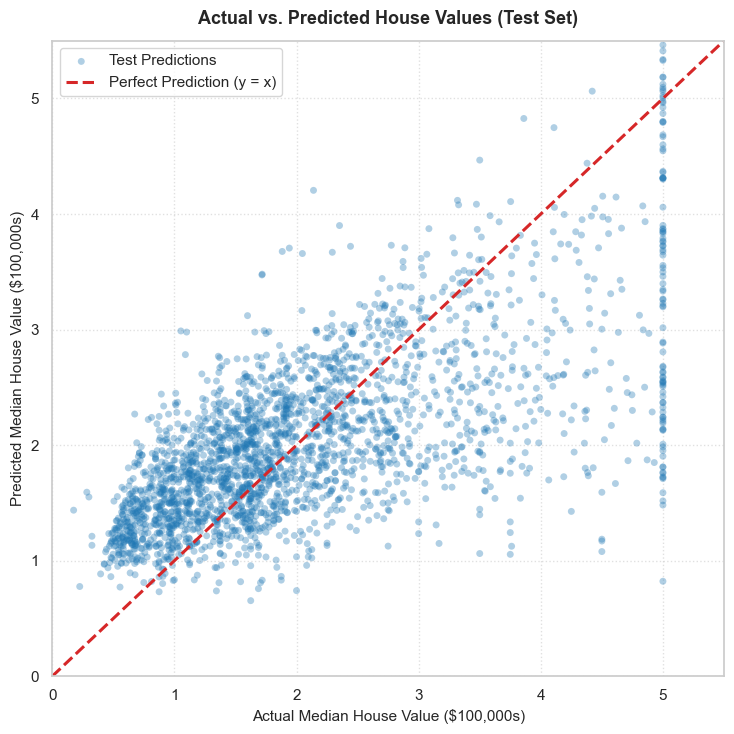

In [18]:
# Scatter plot of Actual vs Predicted House Values on Test Set
plt.figure(figsize=(7.5, 7.5))

# Sample 2,500 points for clear visual rendering
plot_idx = np.random.RandomState(42).choice(len(y_test), size=min(2500, len(y_test)), replace=False)
y_test_plot = y_test.iloc[plot_idx]
y_pred_plot = y_pred[plot_idx]

plt.scatter(y_test_plot, y_pred_plot, alpha=0.35, color='#1f77b4', edgecolors='none', s=25, label='Test Predictions')

# 45-degree reference line
plt.plot([0, 5.5], [0, 5.5], color='#d62728', linestyle='--', linewidth=2.2, label='Perfect Prediction (y = x)')

plt.xlim(0, 5.5)
plt.ylim(0, 5.5)
plt.title("Actual vs. Predicted House Values (Test Set)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Actual Median House Value ($100,000s)", fontsize=11)
plt.ylabel("Predicted Median House Value ($100,000s)", fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


### Visual Analysis:
- **Points near the diagonal**: Indicate accurate predictions where predicted price closely tracks actual census median value.
- **Vertical dispersion**: Reflects variance due to omitted factors (e.g., houses with identical neighborhood income located in different coastal vs inland regions).
- **Horizontal Ceiling at 5.0**: Noticeable horizontal capping where actual values equal 5.0, but linear predictions continue to vary. This highlights the inherent limitation of linear modeling on censored data.


## Section 11: Predict a New Example

We now demonstrate how to use the trained model to predict the median house value for a new, unseen neighborhood with a given median income.

We select `MedInc = 4.5`, which represents a realistic median income of **$45,000** (well within the observed training distribution).


In [19]:
# Define a realistic new median income input
new_medinc_val = 4.5  # $45,000 median annual household income
new_input = pd.DataFrame({'MedInc': [new_medinc_val]})

# Predict using trained model
predicted_val = model.predict(new_input)[0]
predicted_dollars = predicted_val * 100000

print(f"--- New Prediction Demonstration ---")
print(f"Input Median Income       : {new_medinc_val} (i.e. ${new_medinc_val * 10000:,.2f})")
print(f"Predicted MedHouseVal     : {predicted_val:.4f} ($100,000 scale)")
print(f"Predicted House Value ($) : ${predicted_dollars:,.2f}")


--- New Prediction Demonstration ---
Input Median Income       : 4.5 (i.e. $45,000.00)
Predicted MedHouseVal     : 2.3316 ($100,000 scale)
Predicted House Value ($) : $233,162.05


### Interpretation of New Prediction:
For a census block group with a median household income of **$45,000** (`MedInc = 4.5`), the fitted linear regression model predicts a median house value of approximately **2.3316 units**, which translates to **$233,162.05**.

*Crucial Academic Caveat*: This is an illustrative macroeconomic estimate for an entire census block group, not an appraised individual property valuation.


## Section 12: Conclusion and Limitations

### 1. Project Summary
- **Dataset**: Scikit-learn California Housing dataset (20,640 records, 9 continuous numerical attributes).
- **Predictor**: `MedInc` (Median income in $10,000s).
- **Target**: `MedHouseVal` (Median house value in $100,000s).
- **Train/Test Split**: 80% training (16,512 rows), 20% testing (4,128 rows) with `random_state=42`.
- **Learned Regression Equation**:
  $$\text{Predicted MedHouseVal} = 0.4446 + (0.4193 \times \text{MedInc})$$
- **Empirical Test Metrics**:
  - MAE = **0.6299** (~**$62,990.87**)
  - MSE = **0.7091**
  - RMSE = **0.8421** (~**$84,209.01**)
  - $R^2$ = **0.4589** (45.89% variance explained)
- **New Example Prediction**: An input of $45,000 median income yields a predicted median house value of **$233,162.05**.

### 2. Project Limitations & Real-World Considerations
1. **Univariate Simplicity**: Only one feature was utilized. Real-world property valuations depend heavily on multi-factor variables such as geographic location (coastal proximity, latitude, longitude), square footage, number of bedrooms/bathrooms, and property age.
2. **Linearity Assumption**: A linear model assumes a constant rate of change across the entire income spectrum, failing to capture diminishing returns or luxury market non-linearities.
3. **Census Block Aggregates vs. Individual Properties**: The dataset records aggregated census block statistics rather than individual property transaction records.
4. **Historical Context**: The data stems from the 1990 U.S. Census; nominal dollar figures reflect historical market conditions rather than present-day California real estate prices.

---
### Academic Acknowledgement
This project was completed as part of the Machine Learning CIE 2 activity. Faculty reference and Machine Learning learning resources: [https://github.com/Princy2129](https://github.com/Princy2129)
